# Sea ice: bounded fractions and seasonal response

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/31-sea-ice.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/31-sea-ice.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `4fd3739cf53afd17b1185e487b108656ed42a8f8fa2b5e4b1acdb9c01f3ac057`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Sea ice: bounded fractions and seasonal response

**Lesson 31 · Original synthetic data · Independent educational project**

## Objectives

Evolve a bounded concentration; verify its discrete budget; handle masked regions explicitly.

[Previous](30-waves.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/31-sea-ice.ipynb) · [Next](32-ocean.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=31-sea-ice.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

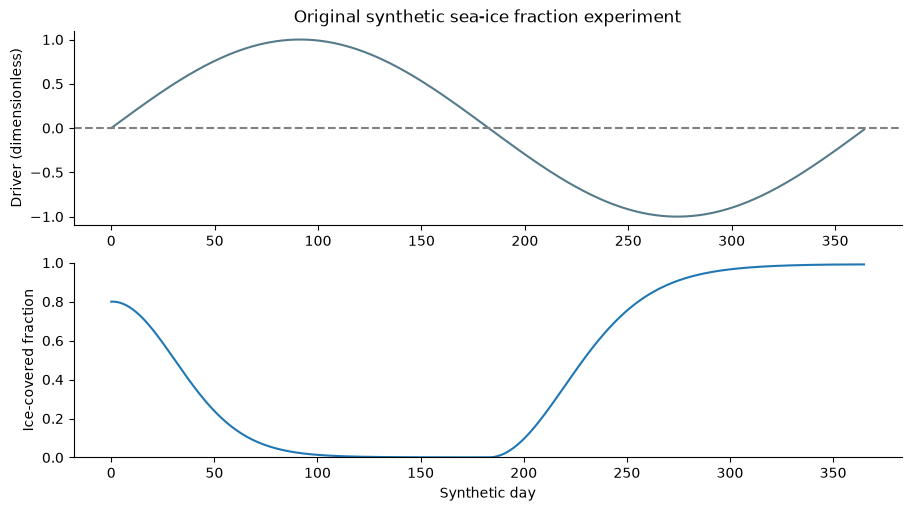

Fraction range 0.001–0.991; masked ocean mean 0.60


In [2]:
day = np.arange(365)
# Dimensionless invented thermal driver: positive means a melt tendency.
driver = np.sin(2*np.pi*day/365)
freeze_rate = .04*np.maximum(-driver, 0)
melt_rate = .06*np.maximum(driver, 0)
concentration = np.zeros(len(day)+1)
concentration[0] = .8
formation, loss = np.zeros(len(day)), np.zeros(len(day))
for i in range(len(day)):
    formation[i] = freeze_rate[i]*(1-concentration[i])
    loss[i] = melt_rate[i]*concentration[i]
    concentration[i+1] = concentration[i]+formation[i]-loss[i]
assert np.all((concentration >= 0) & (concentration <= 1))
assert np.allclose(np.diff(concentration), formation-loss)
# A missing land cell is not a zero-ice ocean cell.
ocean_mask = np.array([True, True, False])
field = np.where(ocean_mask, [.4, .8, 0.], np.nan)
assert np.isclose(np.nanmean(field), .6)
assert np.nanmean(field) != np.nan_to_num(field).mean()
fig, axes = plt.subplots(2, 1, figsize=(9, 5), constrained_layout=True)
axes[0].plot(day, driver, color="#557b8a")
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set(ylabel="Driver (dimensionless)", title="Original synthetic sea-ice fraction experiment")
axes[1].plot(np.arange(len(concentration)), concentration)
axes[1].set(xlabel="Synthetic day", ylabel="Ice-covered fraction", ylim=(0, 1))
plt.show()
print(f"Fraction range {concentration.min():.3f}–{concentration.max():.3f}; masked ocean mean {np.nanmean(field):.2f}")

## Exercise

Change the forcing phase and initial concentration. Preserve the fraction bounds, then explain why masked land must remain distinct from open water.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interpretation and limits

ECMWF's sea-ice ML component studies changing sea-ice and surface-ocean conditions under atmospheric forcing. This original one-cell recurrence is only a bounded-state exercise. It omits ice thickness, transport, salinity, thermodynamics and coupling, and uses no real forcing, reanalysis or trained parameters. Its dimensionless driver is not a physical freezing-point rule.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/ml-earth-system-components/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).